# Can AI help archaeologists decide where to look?
**Instructor — worked solution · approximately 4 hours · Python / Google Colab**

Archaeologists often have more imagery than they have time to inspect. A **tell** is a
mound formed by repeated human occupation. In this workshop, you will use labelled image
tiles from the Enki dataset to rank likely tells for an expert to review.

**Your task:** imagine the team can inspect only **50 tiles**. Train a simple classifier
with at most 100 labelled examples per class, then rank the remaining images. Compare two
ways to describe each image: simple colour/texture measurements and features from a
pretrained image model called DINOv2. Finally, explore what happens when that model is
applied to a different landscape in Cyprus.

**What you will deliver:** a ranked CSV and a short evidence-based recommendation, including
what the model does well and what it cannot tell us. A high score is a review priority,
not proof that a site exists.

### How to use this notebook
1. Open it in [Google Colab](https://colab.research.google.com/) (File → Upload notebook),
   or run it with a local Jupyter kernel. Run cells from top to bottom.
2. Setup downloads a curated sample of 600 real images (about 73 MB); allow about 400 MB
   of free disk. It can take a few minutes. The default workflow runs on CPU.
3. Read the short explanations and inspect the figures. The instructor exercises are solved and can be run in order.
4. In the final section, download the submission ZIP and save your completed notebook.

You need basic Python, pandas and scikit-learn familiarity; the diagrams explain the
modelling and archaeological decisions. A GPU and API accounts are not required.

### Facilitation notes
Share only the participant notebook during the challenge. The saved outputs here were
produced using real Enki images and the pinned foundation model; performance is measured,
not an expected target that participants must reproduce exactly.

Prepare by opening the participant notebook in a fresh Colab session and running setup
and data acquisition before the session. The embedded feature cache removes GPU queues
and model downloads from the critical path. For poor venue connectivity, distribute
`enki_workshop_sample.zip` beforehand and upload it to `archaeology_workshop/`.
Every member is checked against the original ZIP directory's CRC and decoded pixel hashes.

This is an **educational, honour-based holdout** drawn from a public labelled archive.
It is not a secure blind competition: labels remain recoverable from the source data.
Do not claim geographical independence: this archive supplies no verified site grouping
or coordinate manifest. Similar-image deduplication reduces one source of leakage only.

### Your route through the workshop

| Stage | What you do | Why it matters |
|---|---|---|
| 1. Understand the images | Inspect labels and filter similar images | Spot shortcuts and reduce duplication |
| 2. Build a shortlist | Use ranking metrics and fit a simple model | Measure what an expert can review |
| 3. Compare models | Choose a model using validation data | Avoid choosing on the final test |
| 4. Examine limits | Inspect mistakes and apply the model to Cyprus | Understand what might not transfer |
| 5. Report | Freeze the model and export results | Make the recommendation reproducible |

Enki labels come from the source archive; they are not independently verified site identities.
The Cyprus catalogue describes settlement locations and occupation periods, not whether a
site is visible in a modern image. Cyprus images are 1 km square at 10 m per pixel, from one
satellite scene. They are for interpreting transfer, not measuring detection accuracy.

### 1. Setup
Install only the small core dependencies. Existing Colab PyTorch is not replaced.

In [1]:
import importlib.util, os, shutil, subprocess, sys

def install_packages(*requirements):
    if importlib.util.find_spec("pip") is not None:
        command = [sys.executable, "-m", "pip", "install", "-q"]
    elif shutil.which("uv"):
        command = [shutil.which("uv"), "pip", "install", "--python", sys.executable, "-q"]
    else:
        raise RuntimeError("Install pip or uv for this Python environment, then rerun this cell.")
    subprocess.check_call(command + list(requirements))

if not os.environ.get("ARCHAEOLOGY_SKIP_INSTALL"):
    install_packages("imagehash==4.3.2", "ipywidgets>=8,<9", "pillow>=10,<14", "scikit-learn>=1.4,<2",
                     "pandas>=2.1,<4", "matplotlib>=3.8,<4", "requests>=2.31,<3", "tqdm>=4.66,<5")
from IPython.display import display
print("Core dependencies ready.")


Core dependencies ready.


In [ ]:
"""Shared source embedded into both standalone Colab notebooks by build_notebooks.py."""
from pathlib import Path
import base64
import gzip
import hashlib
import io
import json
import os
import random
import time
import zipfile
import struct
import zlib

import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from PIL import Image
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, PrecisionRecallDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

SEED = 42
ENKI_URL = "https://zenodo.org/records/14950565/files/Val_norm.zip?download=1"
ENKI_MD5 = "fbd56ed8039b946eadb6481badf80c95"
ENKI_TRAIN_URL = "https://zenodo.org/records/14950565/files/Normalized_Tell_combined_350.zip?download=1"
CYPRUS_REVISION = "70a5c3d399a2451e1d8dd5eb947eb80055276b44"
CYPRUS_URL = f"https://raw.githubusercontent.com/K-A-Crawford/Cyprus_Settlements/{CYPRUS_REVISION}/Cyprus_Settlements.csv"
MODEL_ID = "facebook/dinov2-small"
MODEL_REVISION = "ed25f3a31f01632728cabb09d1542f84ab7b0056"
PREPROCESS_ID = "rgb-full-frame-bicubic-224-imagenet-mean-std-cls-l2-v1"
CYPRUS_ITEM = "S2A_MSIL2A_20240805T082601_R021_T36SVD_20240805T144559"
ROOT = Path(os.environ.get("ARCHAEOLOGY_WORKSHOP_ROOT", "archaeology_workshop"))


def file_digest(path, algorithm="sha256"):
    h = hashlib.new(algorithm)
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def download(url, destination, md5=None):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and (md5 is None or file_digest(destination, "md5") == md5):
        return destination
    part = destination.with_suffix(destination.suffix + ".part")
    for attempt in range(3):
        try:
            with requests.get(url, stream=True, timeout=(30, 120)) as response:
                response.raise_for_status()
                total = int(response.headers.get("content-length", 0)) or None
                with open(part, "wb") as out, tqdm(total=total, unit="B", unit_scale=True,
                                                    desc=destination.name) as progress:
                    for block in response.iter_content(1024 * 1024):
                        out.write(block)
                        progress.update(len(block))
            if md5 is not None and file_digest(part, "md5") != md5:
                raise ValueError("Checksum mismatch: the download is incomplete or has changed.")
            part.replace(destination)
            return destination
        except (requests.RequestException, ValueError):
            if attempt == 2:
                raise
            time.sleep(2 ** attempt)


def download_enki_sample(manifest_path, destination):
    """Fetch indexed byte ranges, validate ZIP-member CRCs, build a small local ZIP.

    The embedded manifest was prepared from the original ZIP central directory. If a server
    ignores byte ranges, abort rather than accidentally downloading the 1.7 GB archive.
    """
    manifest = json.loads(Path(manifest_path).read_text())
    rows = manifest["members"]
    expected = {r["member"]: r for r in rows}
    destination = Path(destination)
    if destination.exists():
        with zipfile.ZipFile(destination) as z:
            if set(z.namelist()) == set(expected) and all(
                z.getinfo(name).CRC == row["crc"] for name, row in expected.items()
            ) and z.testzip() is None:
                return destination
    cache_dir = destination.parent / "range_cache"
    cache_dir.mkdir(parents=True, exist_ok=True)
    partial = destination.with_suffix(".part")
    groups = sorted(set(r["batch"] for r in rows))
    with requests.Session() as session, zipfile.ZipFile(partial, "w", zipfile.ZIP_DEFLATED) as output:
        for batch in tqdm(groups, desc="Download compact balanced Enki sample"):
            group = [r for r in rows if r["batch"] == batch]
            start = min(r["offset"] for r in group)
            end = max(r["span_end"] for r in group)
            cached = cache_dir / f"{start}-{end}.bin"
            if cached.exists() and cached.stat().st_size == end - start + 1:
                data = cached.read_bytes()
            else:
                for attempt in range(4):
                    try:
                        with session.get(ENKI_TRAIN_URL, headers={"Range": f"bytes={start}-{end}"},
                                         stream=True, timeout=(30, 120)) as response:
                            if response.status_code == 429:
                                delay = min(60, int(response.headers.get("Retry-After", "30")))
                                time.sleep(delay)
                                continue
                            response.raise_for_status()
                            if response.status_code != 206:
                                raise RuntimeError("Server did not honour byte ranges. Use the facilitator's enki_workshop_sample.zip instead.")
                            actual_range = response.headers.get("Content-Range", "")
                            if not actual_range.startswith(f"bytes {start}-{end}/"):
                                raise RuntimeError(f"Unexpected byte range: {actual_range}")
                            data = response.content
                        if len(data) != end - start + 1:
                            raise ValueError("Truncated range download")
                        cached.write_bytes(data)
                        break
                    except requests.RequestException:
                        if attempt == 3:
                            raise
                        time.sleep(2 ** attempt)
                else:
                    raise RuntimeError("Zenodo rate limit persisted; retry later or use the facilitator's sample ZIP.")
            for row in group:
                position = row["offset"] - start
                assert data[position:position + 4] == b"PK\x03\x04"
                name_size, extra_size = struct.unpack_from("<HH", data, position + 26)
                payload_start = position + 30 + name_size + extra_size
                compressed = data[payload_start:payload_start + row["compressed_size"]]
                if row["method"] == 8:
                    payload = zlib.decompress(compressed, -15)
                elif row["method"] == 0:
                    payload = compressed
                else:
                    raise ValueError("Unsupported ZIP compression method")
                assert len(payload) == row["file_size"]
                assert zlib.crc32(payload) & 0xFFFFFFFF == row["crc"], "Archive member checksum mismatch"
                info = zipfile.ZipInfo(row["member"], date_time=(2025, 3, 1, 0, 0, 0))
                info.compress_type = zipfile.ZIP_DEFLATED
                output.writestr(info, payload)
    partial.replace(destination)
    return destination


def index_enki(archive, image_dir):
    """Read only image members, infer classes from actual path components, anonymise paths."""
    image_dir = Path(image_dir)
    image_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    with zipfile.ZipFile(archive) as source:
        members = sorted(source.namelist())
        for name in tqdm(members, desc="Index and audit images"):
            parts = Path(name).parts
            if "__MACOSX" in parts or any(p.startswith(".") for p in parts):
                continue
            if Path(name).suffix.lower() not in {".png", ".jpg", ".jpeg", ".tif", ".tiff"}:
                continue
            classes = set(p.lower() for p in parts) & {"positive", "tell", "negative"}
            if len(classes) != 1:
                raise ValueError(f"Unrecognised class directory: {name}")
            label = int(bool(classes & {"positive", "tell"}))
            tile_id = hashlib.sha256(name.encode()).hexdigest()[:16]
            target = image_dir / f"{tile_id}.png"
            with Image.open(io.BytesIO(source.read(name))) as original:
                rgb = original.convert("RGB")
                pixel_hash = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
                phash = str(imagehash.phash(rgb))
                if not target.exists():
                    rgb.save(target)
                width, height = rgb.size
            rows.append(dict(tile_id=tile_id, member=name, path=str(target), label=label,
                             category=parts[-2], pixel_sha256=pixel_hash, phash=phash,
                             width=width, height=height))
    frame = pd.DataFrame(rows).sort_values("tile_id").reset_index(drop=True)
    assert frame.tile_id.is_unique and set(frame.label) == {0, 1}
    return frame


def deduplicate_images(frame, max_hamming=4):
    """Connected components of close pHashes; exclude mixed-label components; keep one/image family.

    This is an image-similarity audit, NOT a verified geographic/site grouping.
    """
    hashes = [int(x, 16) for x in frame.phash]
    parent = list(range(len(frame)))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, value in enumerate(hashes):
        for j in range(i):
            if (value ^ hashes[j]).bit_count() <= max_hamming:
                parent[find(i)] = find(j)
    audit = frame.copy()
    audit["image_family"] = [f"family_{find(i):04d}" for i in range(len(frame))]
    conflicts = audit.groupby("image_family").label.nunique()
    bad = set(conflicts[conflicts > 1].index)
    clean = (audit.loc[~audit.image_family.isin(bad)]
             .drop_duplicates("image_family").reset_index(drop=True))
    report = {
        "raw_images": len(frame), "exact_duplicate_images": int(frame.pixel_sha256.duplicated().sum()),
        "similarity_families": audit.image_family.nunique(), "mixed_label_families_excluded": len(bad),
        "retained_images": len(clean), "phash_max_hamming": max_hamming,
        "geographic_independence_verified": False,
    }
    return clean, audit, report


def workshop_split(clean, per_class=100):
    # One representative per similarity family has already been selected.
    trainval, test = train_test_split(clean, test_size=0.2, stratify=clean.label, random_state=SEED)
    train_pool, val = train_test_split(trainval, test_size=0.25,
                                     stratify=trainval.label, random_state=SEED)
    train = pd.concat([g.sample(min(per_class, len(g)), random_state=SEED)
                       for _, g in train_pool.groupby("label")])
    splits = {"train": train, "validation": val, "test": test}
    for name, part in splits.items():
        splits[name] = part.sort_values("tile_id").reset_index(drop=True)
    assert not (set(train.image_family) & set(val.image_family))
    assert not (set(train.image_family) & set(test.image_family))
    assert not (set(val.image_family) & set(test.image_family))
    return splits


def contact_sheet(frame, scores=None, n=12, title="Image tiles", show_labels=True):
    subset = frame.head(n).reset_index(drop=True)
    if subset.empty:
        print("No images in this selection.")
        return
    fig, axes = plt.subplots(int(np.ceil(len(subset) / 4)), 4,
                             figsize=(12, 3.1 * int(np.ceil(len(subset) / 4))), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for i, row in subset.iterrows():
        ax = axes.flat[i]
        with Image.open(row.path) as im:
            ax.imshow(im)
        label = f" | y={row.label}" if show_labels and "label" in row else ""
        score = f" | score={float(scores[i]):.3f}" if scores is not None else ""
        ax.set_title(f"{row.tile_id[:9]}{label}{score}", fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def handcrafted_features(paths):
    """Colour distributions, global moments and simple gradient histograms (no pretrained network)."""
    features = []
    for path in tqdm(paths, desc="Colour and texture features"):
        with Image.open(path) as im:
            rgb = np.asarray(im.convert("RGB").resize((64, 64)), dtype=np.float32) / 255
        colour = np.concatenate([np.histogram(rgb[:, :, c], bins=16, range=(0, 1), density=False)[0]
                                 / (64 * 64) for c in range(3)])
        grey = rgb.mean(axis=2)
        dy, dx = np.gradient(grey)
        magnitude = np.sqrt(dx ** 2 + dy ** 2)
        angle = np.arctan2(dy, dx)
        orientation = np.histogram(angle, bins=12, range=(-np.pi, np.pi), weights=magnitude)[0]
        orientation /= orientation.sum() + 1e-8
        moments = np.r_[rgb.mean(axis=(0, 1)), rgb.std(axis=(0, 1)), magnitude.mean(), magnitude.std()]
        features.append(np.r_[colour, moments, orientation])
    return np.asarray(features, dtype=np.float32)


def extract_dino(paths, local_model=None, batch_size=16):
    """Frozen CLS embeddings, full-frame resize to 224x224, ImageNet normalisation, L2 normalisation.

    Model weights and preprocessing are pinned. The same function is used for Enki and Cyprus.
    Imports are lazy so the bundled embedding path also works without torch/transformers.
    """
    import torch
    from transformers import AutoModel

    device = "cuda" if torch.cuda.is_available() else (
        "mps" if torch.backends.mps.is_available() else "cpu")
    torch.manual_seed(SEED)
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    if local_model:
        model = AutoModel.from_pretrained(str(local_model), local_files_only=True)
    else:
        model = AutoModel.from_pretrained(MODEL_ID, revision=MODEL_REVISION,
                                          cache_dir=str(ROOT / "model_cache"))
    model = model.eval().to(device)
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    vectors = []
    started = time.perf_counter()
    with torch.inference_mode():
        for start in tqdm(range(0, len(paths), batch_size), desc=f"DINOv2 ({device})"):
            batch = []
            for path in paths[start:start + batch_size]:
                with Image.open(path) as im:
                    arr = np.asarray(im.convert("RGB").resize((224, 224), Image.Resampling.BICUBIC),
                                     dtype=np.float32).copy() / 255
                batch.append((torch.from_numpy(arr).permute(2, 0, 1) - mean) / std)
            tensor = torch.stack(batch).to(device)
            feature = model(pixel_values=tensor).last_hidden_state[:, 0]
            feature = torch.nn.functional.normalize(feature.float(), dim=1)
            vectors.append(feature.cpu().numpy())
    print(f"Encoded {len(paths)} images in {time.perf_counter() - started:.1f}s on {device}.")
    return np.concatenate(vectors).astype(np.float32)


def load_embedding_cache(frame, cache_path):
    with np.load(cache_path, allow_pickle=False) as cache:
        assert str(cache["model_id"]) == MODEL_ID
        assert str(cache["revision"]) == MODEL_REVISION
        assert str(cache["preprocessing"]) == PREPROCESS_ID
        positions = {str(k): i for i, k in enumerate(cache["tile_ids"])}
        indices = [positions[k] for k in frame.tile_id]
        expected = cache["pixel_sha256"][indices].astype(str)
        assert np.array_equal(expected, frame.pixel_sha256.to_numpy()), "Image/cache mismatch."
        return cache["embeddings"][indices].astype(np.float32)


def partition_features(frame, features, splits):
    positions = {key: i for i, key in enumerate(frame.tile_id)}
    return {name: features[[positions[k] for k in subset.tile_id]]
            for name, subset in splits.items()}


def ranking_indices(scores):
    values = np.asarray(scores, dtype=float)
    if values.ndim != 1 or not np.isfinite(values).all():
        raise ValueError("Scores must be a finite one-dimensional array.")
    # Stable tie-breaking follows the tile_id-sorted input manifest.
    return np.argsort(-values, kind="stable")


def nearest_examples(query_vector, train_vectors, train_frame, k=4):
    similarity = train_vectors @ query_vector
    order = ranking_indices(similarity)[:k]
    return train_frame.iloc[order].reset_index(drop=True), similarity[order]


def learning_curve_rows(estimator, X, y, X_val, y_val, metric_fn, k=50):
    rows = []
    for budget in (10, 25, 50, 100):
        for seed in (0, 1, 2):
            rng = np.random.default_rng(seed)
            if any((y == label).sum() < budget for label in (0, 1)):
                continue
            indices = np.concatenate([rng.choice(np.flatnonzero(y == label), budget, replace=False)
                                      for label in (0, 1)])
            fitted = clone(estimator).fit(X[indices], y[indices])
            scores = fitted.predict_proba(X_val)[:, 1]
            rows.append(dict(labels_per_class=budget, seed=seed, **metric_fn(y_val, scores, k)))
    return pd.DataFrame(rows)


def write_submission(frame, scores, destination):
    scores = np.asarray(scores, dtype=float)
    if len(scores) != len(frame):
        raise ValueError("Exactly one score per test tile is required.")
    order = ranking_indices(scores)
    output = pd.DataFrame({"tile_id": frame.tile_id.to_numpy()[order], "score": scores[order],
                           "rank": np.arange(1, len(scores) + 1)})
    assert output.tile_id.is_unique
    output.to_csv(destination, index=False)
    return output


def score_submission(submission, truth, metric_fn, k=50):
    if not submission.tile_id.is_unique or set(submission.tile_id) != set(truth.tile_id):
        raise ValueError("Submission must contain every test tile exactly once, with no extra IDs.")
    aligned = truth[["tile_id", "label"]].merge(submission[["tile_id", "score"]],
                                               on="tile_id", how="left", validate="one_to_one")
    return metric_fn(aligned.label.to_numpy(), aligned.score.to_numpy(), k)


def make_cyprus_bundle(phases, output_dir, local_model=None):
    """Instructor refresh utility: public Sentinel-2 COG windows; no paid account required.

    Normal participant runs use the verified, embedded bundle instead of live STAC requests.
    """
    import rasterio
    from rasterio.warp import transform as transform_points
    from rasterio.windows import Window
    import planetary_computer

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    item_url = f"https://planetarycomputer.microsoft.com/api/stac/v1/collections/sentinel-2-l2a/items/{CYPRUS_ITEM}"
    response = requests.get(item_url, timeout=60)
    response.raise_for_status()
    item = response.json()
    points = phases.drop_duplicates("ID").copy()
    for c in ("Long_Cord", "Lat_Cord", "Longitude", "Latitude"):
        points[c] = pd.to_numeric(points[c], errors="coerce")
    candidates = points.loc[(points.LocQual.str.strip() == "A") &
                            points.Long_Cord.between(32.4, 32.85) &
                            points.Lat_Cord.between(34.72, 35.12)]
    candidates = candidates.sort_values("ID").sample(frac=1, random_state=SEED)
    rows = []
    known_xy = points[["Longitude", "Latitude"]].dropna().to_numpy()
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY="3",
                       GDAL_HTTP_RETRY_DELAY="2"):
        with rasterio.open(planetary_computer.sign(item["assets"]["visual"]["href"])) as rgb, \
             rasterio.open(planetary_computer.sign(item["assets"]["SCL"]["href"])) as scl:
            assert rgb.crs.to_epsg() == 32636
            for _, site in candidates.iterrows():
                if len(rows) >= 12:
                    break
                x, y = transform_points("EPSG:4326", rgb.crs, [site.Long_Cord], [site.Lat_Cord])
                pair = []
                for kind, px, py in (("catalogued_location", x[0], y[0]),
                                     ("unlabelled_background", x[0] + 2000, y[0])):
                    if kind == "unlabelled_background" and np.linalg.norm(known_xy - [px, py], axis=1).min() < 750:
                        break
                    rr, cc = rgb.index(px, py)
                    if not (50 <= rr < rgb.height - 50 and 50 <= cc < rgb.width - 50):
                        break
                    # 1 km x 1 km at 10 m/pixel; SCL has 20 m pixels.
                    image = rgb.read([1, 2, 3], window=Window(cc - 50, rr - 50, 100, 100))
                    sr, sc = scl.index(px, py)
                    quality = scl.read(1, window=Window(sc - 25, sr - 25, 50, 50))
                    clear_land = float(np.isin(quality, [4, 5, 7]).mean())
                    if clear_land < 0.9 or (image.sum(axis=0) == 0).mean() > 0.05:
                        break
                    tile_id = f"{site.ID}_{'site' if kind == 'catalogued_location' else 'background'}"
                    filename = tile_id + ".png"
                    Image.fromarray(image.transpose(1, 2, 0)).save(output_dir / filename)
                    lon, lat = transform_points(rgb.crs, "EPSG:4326", [px], [py])
                    pair.append(dict(tile_id=tile_id, filename=filename, kind=kind, paired_site=site.ID,
                                     lon=lon[0], lat=lat[0], LocQual=site.LocQual.strip(),
                                     clear_land_fraction=clear_land, gsd_m=10, footprint_m=1000,
                                     acquisition=item["properties"]["datetime"], item_id=CYPRUS_ITEM))
                if len(pair) == 2:
                    rows.extend(pair)
    manifest = pd.DataFrame(rows).sort_values("tile_id").reset_index(drop=True)
    if len(manifest) != 12:
        raise RuntimeError(f"Expected six usable pairs; found {len(manifest)} chips.")
    manifest.to_csv(output_dir / "manifest.csv", index=False)
    vectors = extract_dino([str(output_dir / f) for f in manifest.filename], local_model=local_model)
    np.savez_compressed(output_dir / "embeddings.npz", tile_ids=manifest.tile_id.to_numpy(dtype=str),
                        embeddings=vectors, model_id=MODEL_ID, revision=MODEL_REVISION,
                        preprocessing=PREPROCESS_ID)
    metadata = dict(item_url=item_url, item_id=CYPRUS_ITEM, acquisition=item["properties"]["datetime"],
                    attribution="Contains modified Copernicus Sentinel data (2024), accessed through Microsoft Planetary Computer.",
                    interpretation="Landscape-context stress test, not archaeological detection ground truth.")
    (output_dir / "provenance.json").write_text(json.dumps(metadata, indent=2))
    return manifest

random.seed(SEED)
np.random.seed(SEED)
ROOT.mkdir(parents=True, exist_ok=True)


The next cell unpacks the provided image features, Cyprus catalogue and 12 satellite images.
**Run it; you do not need to edit it.** The Enki images themselves are downloaded next.
Cached features let the workshop run without downloading or running the pretrained model.

In [3]:
# Embedded reproducible workshop assets; no edits needed.
ASSET_B64 = "..."
assets = ROOT / "assets"
assets.mkdir(exist_ok=True)
with zipfile.ZipFile(io.BytesIO(base64.b64decode(ASSET_B64))) as bundle:
    for member in bundle.infolist():
        target = (assets / member.filename).resolve()
        if not target.is_relative_to(assets.resolve()):
            raise ValueError("Unsafe bundle path")
    bundle.extractall(assets)
del ASSET_B64
print("Unpacked frozen embeddings, Cyprus catalogue and 12 Sentinel-2 chips.")


Unpacked frozen embeddings, Cyprus catalogue and 12 Sentinel-2 chips.


### 2. Meet the Enki images

**Question:** what examples are we learning from, and can very similar images make a
model look better than it is?

The workshop uses 600 archive images: 300 source-labelled negative examples and 300
positives from five landscape categories. A positive is labelled as a tell in the source;
a negative comes from its negative folder. The sample is deliberately balanced for teaching,
so its 50% positive rate is not an estimate of how common tells are in the world.

Run the next two cells. They download and verify the selected images, group visually similar
images, remove contradictory groups, and keep one image per group. Then they split the
remaining images into training, validation and test sets and show some training images.
Context categories are for inspection, not model inputs.

**Why filter?** Near-duplicates across splits can give an overly optimistic result. Visual
similarity checks miss some repeated sites, however, and do not prove geographic independence.
These workshop splits are not the original authors’ experimental splits.

In [4]:
archive = download_enki_sample(assets / "sample_manifest.json", ROOT / "enki_workshop_sample.zip")
all_images = index_enki(archive, ROOT / "images")
clean_images, duplicate_audit, audit_report = deduplicate_images(all_images)
display(pd.Series(audit_report, name="audit"))
display(all_images.groupby(["label", "category"]).size().rename("images").to_frame())
print("Image dimensions:", all_images[["width", "height"]].value_counts().to_dict())


Index and audit images:   0%|          | 0/600 [00:00<?, ?it/s]

Index and audit images:  46%|████▌     | 275/600 [00:00<00:00, 2730.59it/s]

Index and audit images:  92%|█████████▏| 549/600 [00:00<00:00, 584.11it/s] 

Index and audit images: 100%|██████████| 600/600 [00:00<00:00, 628.66it/s]

raw_images                            600
exact_duplicate_images                  2
similarity_families                   593
mixed_label_families_excluded           0
retained_images                       593
phash_max_hamming                       4
geographic_independence_verified    False
Name: audit, dtype: object

images
label category                            
0     Negative                         300
1     Agricoltural_areas                60
      Continuos_discontinuos_urban      60
      Desert_bare                       60
      Dry_arable                        60
      Water                             60

Image dimensions: {(350, 350): 344, (64, 64): 256}


In [ ]:
splits = workshop_split(clean_images, per_class=100)
train, validation, test = (splits[k] for k in ("train", "validation", "test"))
REVIEW_BUDGET = 50
display(pd.DataFrame({name: part.label.value_counts().sort_index()
                      for name, part in (("train", train), ("validation", validation))}).rename_axis("label"))
contact_sheet(train.sample(12, random_state=SEED), title="Training examples: 1=tell; 0=background")
# The remaining unused training-pool images are not extra labels for this challenge.
print("Do not inspect test labels or test images until model selection is frozen.")


#### What is in this teaching sample?
The left chart counts the **original sampled images** by archive context and label; these
are source categories, not independent regions. The right chart shows what remains after
similarity filtering and how the retained images are allocated. Unused images belong to
the training pool but are withheld to enforce the label budget. The balanced sampling
was designed for teaching and does not estimate the prevalence of tells in the landscape.

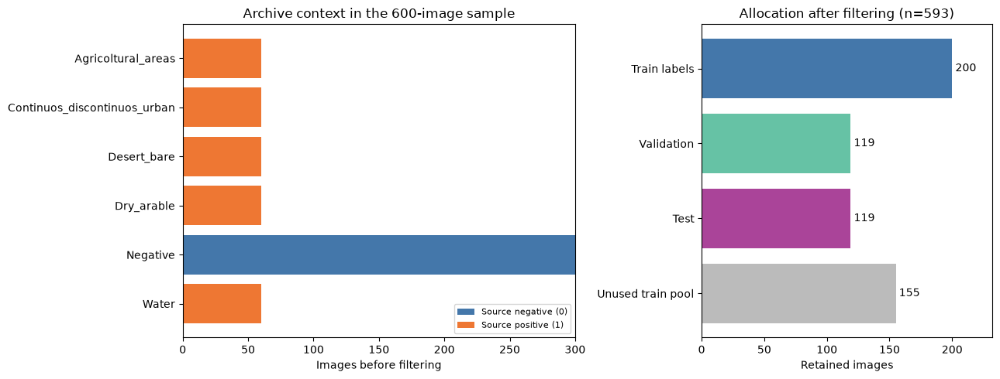

In [ ]:
counts = (all_images.groupby(["category", "label"]).size().unstack(fill_value=0)
          .reindex(columns=[0, 1], fill_value=0).sort_index())
used = [len(train), len(validation), len(test)]
allocation = used + [len(clean_images) - sum(used)]
fig, (ax_context, ax_split) = plt.subplots(1, 2, figsize=(13, 5),
                                           gridspec_kw={"width_ratios": [1.35, 1]})
positions = np.arange(len(counts))
ax_context.barh(positions, counts[0], color="#4477aa", label="Source negative (0)")
ax_context.barh(positions, counts[1], left=counts[0], color="#ee7733", label="Source positive (1)")
ax_context.set_yticks(positions, labels=counts.index.astype(str))
ax_context.invert_yaxis()
ax_context.set(xlabel="Images before filtering", title="Archive context in the 600-image sample")
ax_context.legend(loc="lower right", fontsize=8)
bars = ax_split.barh(["Train labels", "Validation", "Test", "Unused train pool"], allocation,
                     color=["#4477aa", "#66c2a5", "#aa4499", "#bbbbbb"])
ax_split.invert_yaxis()
ax_split.bar_label(bars, padding=3)
ax_split.set(xlabel="Retained images", title=f"Allocation after filtering (n={len(clean_images)})")
ax_split.margins(x=0.16)
fig.tight_layout()
plt.show()


**Discuss:** What visual evidence distinguishes the classes? Could rendering, masking or
land-cover context be a shortcut? Why does duplicate removal not establish geographic transfer?
Raw accuracy is a poor description of a ranking system with a limited review budget.

**Worked interpretation:** several displayed source-negative training tiles are visibly
pixelated, while several positive tiles show finer detail. This is an observed rendering
shortcut worth testing, not proof of what the encoder uses. Look for class-correlated
saturation and land-cover composition too. Source subfolder names describe context categories;
they are not independent surveys or verified geographic regions. Good holdout results
may still depend on similar landscapes or unrecognised repeated sites. Neither an image
hash nor a random split establishes that the model generalises to a new country.

**Why keep three partitions?** Training fits candidate models; validation compares them;
the untouched test set provides one final assessment after the choice is frozen. Similarity
filtering reduces image duplication but does not make these independent geographic regions.

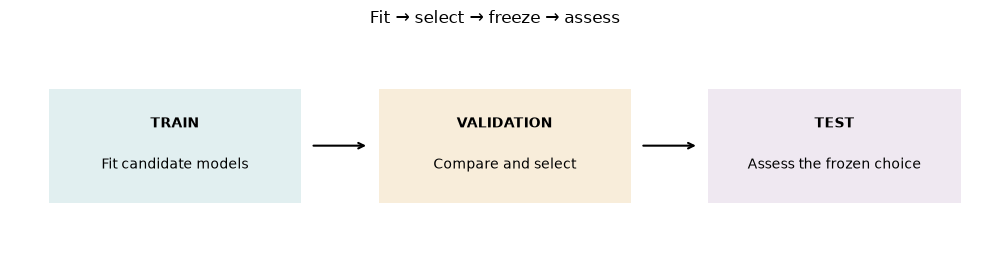

In [ ]:
fig, ax = plt.subplots(figsize=(10, 2.8))
roles = [
    ("TRAIN", "Fit candidate models", "#e1eff0"),
    ("VALIDATION", "Compare and select", "#f8edda"),
    ("TEST", "Assess the frozen choice", "#efe8f1"),
]
for i, (name, role, colour) in enumerate(roles):
    x = .04 + i * .34
    ax.add_patch(plt.Rectangle((x, .25), .26, .5, transform=ax.transAxes,
                               facecolor=colour, edgecolor="none"))
    ax.text(x + .13, .58, name, transform=ax.transAxes, ha="center", weight="bold")
    ax.text(x + .13, .40, role, transform=ax.transAxes, ha="center", fontsize=10)
    if i < 2:
        ax.annotate("", xy=(x + .33, .5), xytext=(x + .27, .5),
                    xycoords="axes fraction", arrowprops={"arrowstyle": "->", "lw": 1.5})
ax.set_title("Fit → select → freeze → assess")
ax.axis("off")
fig.tight_layout()
plt.show()


### 3. Exercise 1 — measure a useful shortlist

**Question:** if an expert can inspect only `k` tiles, how many known positives reach the
shortlist? The picture below uses an invented ranking to show the idea.

Run the example `ranking_metrics(y_true, scores, k)` below. It returns:
- `hits`: number of positive tiles among the top `k` scores.
- `reviewed`: number actually reviewed, `min(k, number_of_tiles)`.
- `recall_at_k`: hits divided by *all* positive tiles.
- `precision_at_k`: hits divided by tiles reviewed.
- `AP`: average precision, a measure over the complete ranking.

`y_true` contains source labels (1 or 0); `scores` are model priorities. Higher scores rank
first. If there are no positives, return `np.nan` for AP and recall. Use the provided stable
ordering helper for ties. Run the check cell, then experiment with the optional change in the comments.

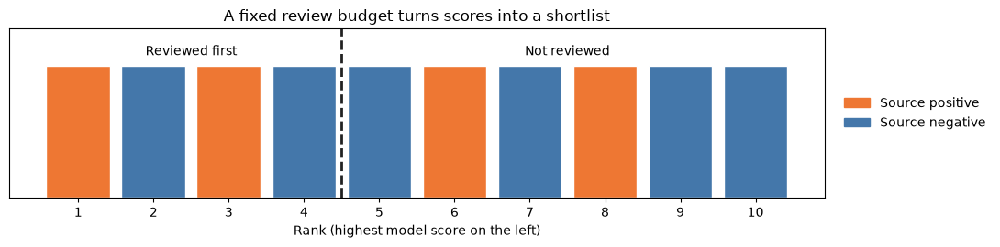

In [ ]:
# A schematic, not a result from the Enki test set.
from matplotlib.patches import Patch
example_labels = [1, 0, 1, 0, 0, 1, 0, 1, 0, 0]
example_budget = 4
fig, ax = plt.subplots(figsize=(11, 2.8))
colors = ["#ee7733" if label else "#4477aa" for label in example_labels]
ax.bar(np.arange(1, 11), np.ones(10), color=colors, edgecolor="white", width=0.85)
ax.axvline(example_budget + 0.5, color="#222222", linestyle="--", linewidth=2)
ax.text(2.5, 1.08, "Reviewed first", ha="center", fontsize=10)
ax.text(7.5, 1.08, "Not reviewed", ha="center", fontsize=10)
ax.set_xticks(np.arange(1, 11))
ax.set(xlabel="Rank (highest model score on the left)", yticks=[],
       title="A fixed review budget turns scores into a shortlist")
ax.legend(handles=[Patch(color="#ee7733", label="Source positive"),
                   Patch(color="#4477aa", label="Source negative")],
          loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
ax.set_ylim(0, 1.28)
fig.tight_layout()
plt.show()


In this illustration, each rectangle is a tile and the dashed line is the review limit.
Precision asks what fraction of reviewed tiles are positive; recall asks what fraction of
all positives were reviewed. The colors represent known labels for evaluation, not information
available to a reviewer before labels are known. Average precision considers the full ranking.

In [6]:
def ranking_metrics(y_true, scores, k=50):
    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)
    if y_true.ndim != 1 or len(y_true) != len(scores) or len(y_true) == 0:
        raise ValueError("Use nonempty, aligned one-dimensional arrays.")
    if not set(np.unique(y_true)).issubset({0, 1}) or k < 1:
        raise ValueError("Binary labels and k >= 1 are required.")
    order = ranking_indices(scores)
    budget = min(int(k), len(y_true))
    hits = int(y_true[order[:budget]].sum())
    positives = int(y_true.sum())
    return {
        "AP": float(average_precision_score(y_true, scores)) if positives else float("nan"),
        "recall_at_k": hits / positives if positives else float("nan"),
        "precision_at_k": hits / budget,
        "hits": hits, "reviewed": budget,
    }


In [7]:
toy = ranking_metrics(np.array([1, 0, 1, 0]), np.array([.9, .8, .7, .1]), k=2)
assert np.isclose(toy["recall_at_k"], .5)
assert np.isclose(toy["precision_at_k"], .5)
assert np.isclose(toy["AP"], 5 / 6)
assert toy["hits"] == 1 and toy["reviewed"] == 2
assert ranking_metrics([1, 0], [.2, .1], k=10)["reviewed"] == 2
assert np.isnan(ranking_metrics([0, 0], [.9, .1], k=1)["recall_at_k"])
print("Metric checks passed.")


Metric checks passed.


### 4. Describe each image in two ways

A classifier needs numbers, not image files. We compare two sets of numbers for the same tiles:

- **Colour and texture:** simple summaries of colours, brightness and edges. This is our baseline.
- **DINOv2:** a pretrained general-purpose image model turns each tile into a 384-number
  description called an *embedding*. Its encoder stays frozen: it is not trained on our labels.

Run the next cell to calculate the baseline and load the provided DINOv2 features. Comparing
both on the same splits helps us ask whether the pretrained representation adds value here.
DINOv2 is not specialised for Earth observation. The same DINOv2 preprocessing is used
for Enki and Cyprus.

In [8]:
X_handcrafted = handcrafted_features(clean_images.path.tolist())
X_dino = load_embedding_cache(clean_images, assets / "enki_embeddings.npz")
feature_sets = {
    "colour_texture": partition_features(clean_images, X_handcrafted, splits),
    "dinov2": partition_features(clean_images, X_dino, splits),
}
y_train = train.label.to_numpy()
y_val = validation.label.to_numpy()
print("Feature shapes:", X_handcrafted.shape, X_dino.shape)
print("Pinned model:", MODEL_ID, MODEL_REVISION)


Colour and texture features:   0%|          | 0/593 [00:00<?, ?it/s]

Colour and texture features:   7%|▋         | 40/593 [00:00<00:01, 398.43it/s]

Colour and texture features:  15%|█▍        | 88/593 [00:00<00:01, 439.02it/s]

Colour and texture features:  22%|██▏       | 132/593 [00:00<00:01, 428.34it/s]

Colour and texture features:  30%|███       | 179/593 [00:00<00:00, 441.42it/s]

Colour and texture features:  38%|███▊      | 224/593 [00:00<00:00, 436.58it/s]

... (5 outputs left out)

Colour and texture features:  85%|████████▌ | 506/593 [00:01<00:00, 423.83it/s]

Colour and texture features:  93%|█████████▎| 552/593 [00:01<00:00, 433.95it/s]

Colour and texture features: 100%|██████████| 593/593 [00:01<00:00, 436.05it/s]

Feature shapes: (593, 68) (593, 384)
Pinned model: facebook/dinov2-small ed25f3a31f01632728cabb09d1542f84ab7b0056


**Optional:** the next cell normally reuses the cached features and needs no GPU. Leave
`RECOMPUTE_DINO = False` for the main workshop. To reproduce the features yourself, set it to
`True`; this downloads model weights (~90 MB) and may take time on a CPU. In Colab you can
select a T4 GPU if one is available. Do this before fitting models.

In [9]:
RECOMPUTE_DINO = False
if RECOMPUTE_DINO:
    install_packages("transformers==4.57.6")
    fresh = extract_dino(clean_images.path.tolist())
    print("Mean cosine agreement with cache:", np.mean(np.sum(fresh * X_dino, axis=1)))
    X_dino = fresh
    feature_sets["dinov2"] = partition_features(clean_images, X_dino, splits)
else:
    print("Using verified cached embeddings; no GPU required.")


Using verified cached embeddings; no GPU required.


### 5. Exercise 2 — build a simple classifier

**Question:** can a small model learn to score tiles using their features?

The `make_probe(C)` example returns a scikit-learn pipeline with `StandardScaler` followed by
`LogisticRegression`. The scaler learns feature ranges from the training data inside the
pipeline, so validation data cannot influence fitting. `C` controls regularisation: smaller
values constrain the classifier more strongly. Run the check to fit a colour/texture baseline
and display its validation metrics.

In [10]:
def make_probe(C=1.0):
    # Fitting the pipeline on training data fits the scaler there, too.
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(C=C, class_weight="balanced", max_iter=2000, random_state=SEED),
    )


In [11]:
baseline = make_probe(C=1.0).fit(feature_sets["colour_texture"]["train"], y_train)
baseline_val = baseline.predict_proba(feature_sets["colour_texture"]["validation"])[:, 1]
display(pd.Series(ranking_metrics(y_val, baseline_val, REVIEW_BUDGET), name="baseline"))
assert len(baseline.steps) == 2
assert not hasattr(make_probe().steps[0][1], "mean_")


AP                 0.864333
recall_at_k        0.666667
precision_at_k     0.800000
hits              40.000000
reviewed          50.000000
Name: baseline, dtype: float64

### 6. Exercise 3 — choose a model fairly

The next cell compares both feature sets and four `C` values: `0.01`, `0.1`, `1`, `10`. It fits each candidate
on training data and scores it on validation data. It chooses the highest validation recall at
the 50-tile budget, using AP to break ties. This gives eight candidates.

**Why validation?** Choosing with the test set would make the final assessment less independent.
Keep the test set untouched until your choice is frozen. Report the baseline if it wins.
Run the following check to see the comparison and precision–recall curves.

In [12]:
candidate_models = {}
validation_rows = []
for representation, matrices in feature_sets.items():
    for C in (0.01, 0.1, 1.0, 10.0):
        estimator = make_probe(C).fit(matrices["train"], y_train)
        scores = estimator.predict_proba(matrices["validation"])[:, 1]
        key = f"{representation}_C{C:g}"
        candidate_models[key] = (representation, estimator)
        validation_rows.append({"model": key, "representation": representation, "C": C,
                                **ranking_metrics(y_val, scores, REVIEW_BUDGET)})
validation_results = pd.DataFrame(validation_rows).sort_values(
    ["recall_at_k", "AP", "model"], ascending=[False, False, True]
).reset_index(drop=True)
best_key = validation_results.iloc[0]["model"]
best_representation, best_model = candidate_models[best_key]
display(validation_results)
print("Selected using validation only:", best_key)


,model,representation,C,AP,recall_at_k,precision_at_k,hits,reviewed
0,dinov2_C1,dinov2,1.00,0.996247,0.833333,1.00,50,50
1,dinov2_C0.1,dinov2,0.10,0.995955,0.833333,1.00,50,50
2,dinov2_C10,dinov2,10.00,0.995732,0.833333,1.00,50,50
3,dinov2_C0.01,dinov2,0.01,0.995340,0.833333,1.00,50,50
4,colour_texture_C10,colour_texture,10.00,0.865004,0.700000,0.84,42,50
5,colour_texture_C1,colour_texture,1.00,0.864333,0.666667,0.80,40,50
6,colour_texture_C0.1,colour_texture,0.10,0.828614,0.666667,0.80,40,50
7,colour_texture_C0.01,colour_texture,0.01,0.737186,0.633333,0.76,38,50


Selected using validation only: dinov2_C1


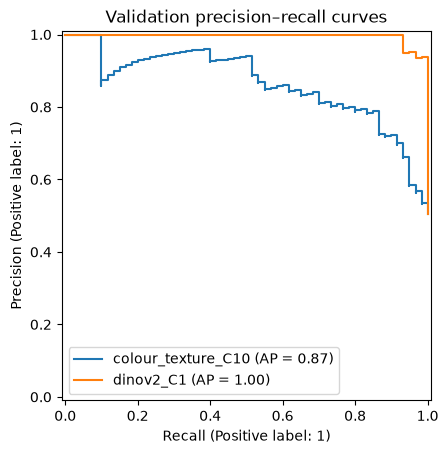

In [13]:
assert len(validation_results) == 8
assert set(validation_results.representation) == {"colour_texture", "dinov2"}
assert best_key in candidate_models
validation_results.to_csv(ROOT / "validation_results.csv", index=False)
for representation in feature_sets:
    key = validation_results.loc[validation_results.representation == representation, "model"].iloc[0]
    fitted = candidate_models[key][1]
    scores = fitted.predict_proba(feature_sets[representation]["validation"])[:, 1]
    PrecisionRecallDisplay.from_predictions(y_val, scores, name=key, ax=plt.gca())
plt.title("Validation precision–recall curves")
plt.show()


**Worked interpretation:** evaluate the measured improvement, not the model's reputation.
A bigger AP does not guarantee more positives within the first 50 reviews. A large gap
between conventional and pretrained features supports using the representation on this
split; it does not establish general archaeological detection or superiority across regions.
Eight validation comparisons already create selection optimism. Keep the final test for one
frozen evaluation, and keep any future comparisons on new development splits.

### 7. How many labels help, and where does the model struggle?

The next cell fits the DINOv2 classifier with 10, 25, 50 and 100 labelled training examples
per class. It repeats each selection three times and plots validation recall at the review
budget. A rising curve suggests more labels helped; a flat curve suggests diminishing returns.
The variation reflects these three training samples, not independent geographic regions.

The following cell shows high-scoring source negatives and low-scoring source positives.
Look for landscape patterns, rendering or other cues that could explain the scores; images
alone cannot prove why the model made a decision.

AP           recall_at_k          
                      mean       std        mean       std
labels_per_class                                          
10                0.959049  0.012212    0.772222  0.034694
25                0.981171  0.015209    0.816667  0.016667
50                0.981991  0.022696    0.816667  0.016667
100               0.996247  0.000000    0.833333  0.000000

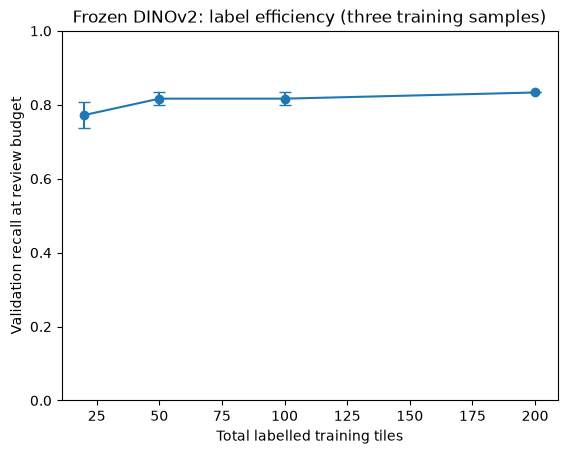

In [14]:
best_dino_key = validation_results.loc[validation_results.representation == "dinov2", "model"].iloc[0]
dino_probe = candidate_models[best_dino_key][1]
curve = learning_curve_rows(dino_probe, feature_sets["dinov2"]["train"], y_train,
                           feature_sets["dinov2"]["validation"], y_val,
                           ranking_metrics, REVIEW_BUDGET)
display(curve.groupby("labels_per_class")[["AP", "recall_at_k"]].agg(["mean", "std"]))
summary = curve.groupby("labels_per_class").recall_at_k.agg(["mean", "std"])
plt.errorbar(summary.index * 2, summary["mean"], yerr=summary["std"], marker="o", capsize=4)
plt.xlabel("Total labelled training tiles")
plt.ylabel("Validation recall at review budget")
plt.ylim(0, 1)
plt.title("Frozen DINOv2: label efficiency (three training samples)")
plt.show()
curve.to_csv(ROOT / "learning_curve.csv", index=False)


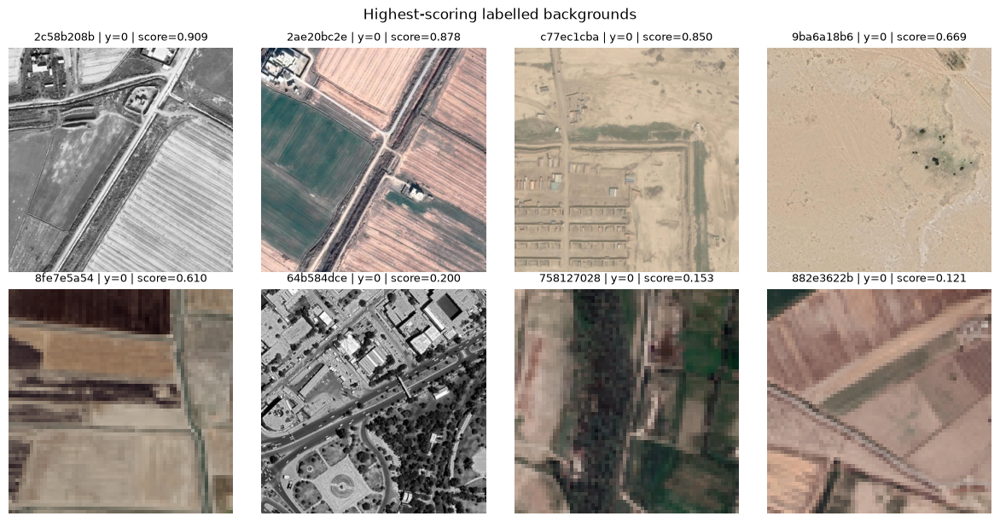

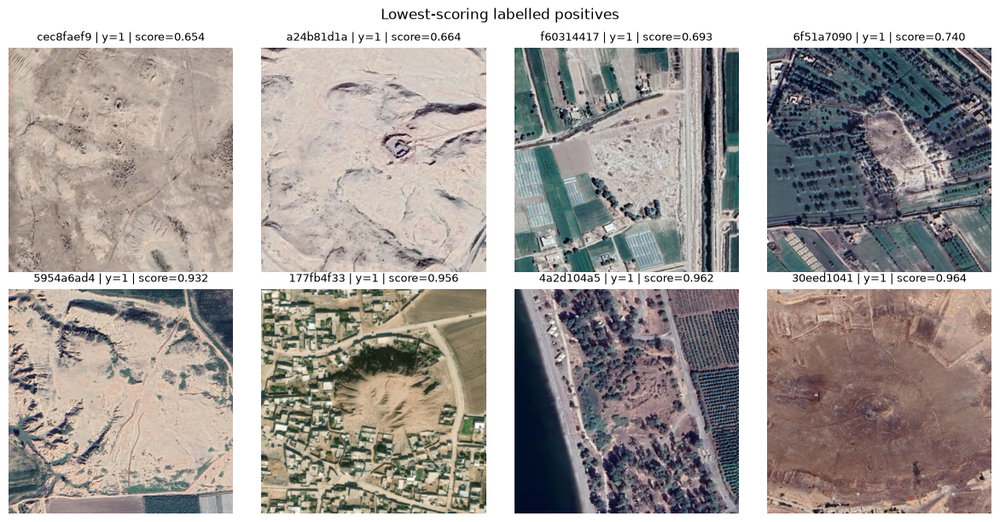

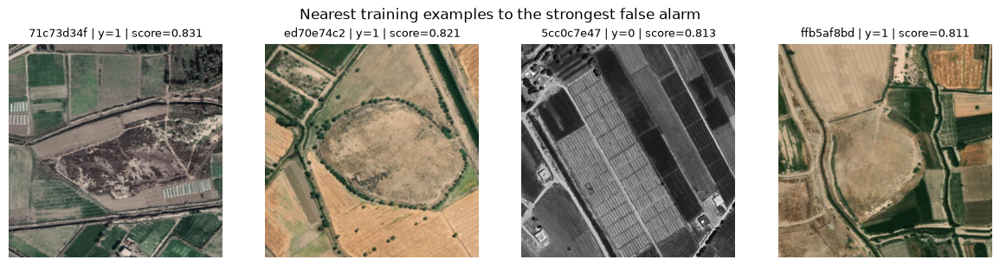

In [15]:
dino_val_scores = dino_probe.predict_proba(feature_sets["dinov2"]["validation"])[:, 1]
failures = validation.copy()
failures["score"] = dino_val_scores
false_alarms = failures.loc[failures.label == 0].sort_values("score", ascending=False)
missed = failures.loc[failures.label == 1].sort_values("score")
contact_sheet(false_alarms, false_alarms.score.to_numpy(), n=8, title="Highest-scoring labelled backgrounds")
contact_sheet(missed, missed.score.to_numpy(), n=8, title="Lowest-scoring labelled positives")
# Inspect model neighbours for one difficult validation image.
query_index = int(np.argmax(np.where(y_val == 0, dino_val_scores, -np.inf)))
neighbours, similarity = nearest_examples(feature_sets["dinov2"]["validation"][query_index],
                                          feature_sets["dinov2"]["train"], train)
contact_sheet(neighbours, similarity, n=4, title="Nearest training examples to the strongest false alarm")


**Your interpretation:** use the images to suggest two reasons a source-negative tile might
rank highly and one reason a source-positive tile might rank poorly. Fill in the dictionary
below and note what additional evidence would help an archaeologist check your ideas.

In [16]:
error_notes = {
    "false_alarm_1": "Validation tile 2c58b208b shows field boundaries and a road junction; it receives a high score despite its source-negative label. Linear landscape structure is a plausible confounder.",
    "false_alarm_2": "Tile c77ec1cba contains a rectilinear built or disturbed area. Its high source-negative score suggests that geometry and exposed-soil context merit inspection; this is not a causal attribution.",
    "missed_positive": "The lowest-ranked source-positive cec8faef9 shows muted, disturbed-looking terrain. It may fall outside a limited shortlist even with a score above 0.5; shortlist misses are not the same as thresholded false negatives.",
    "next_evidence_needed": "Expert image review, source provenance, additional dates and finer-resolution imagery; field evidence for archaeological confirmation.",
}
# These visual interpretations refer to the pinned validation contact sheet.
# They are not new archaeological ground-truth annotations or causal explanations.


### 8. Exercise 4 — understand the Cyprus catalogue

**Question:** how many distinct settlements are represented, and how reliable are their
locations? Each catalogue row is an occupation phase, so a settlement can appear multiple
times. The next cell loads the catalogue. Run `summarise_sites(phases)` to return one row
per settlement ID and run the check to plot the sites.

Use `Long_Cord` and `Lat_Cord` for longitude and latitude in degrees. Despite their names,
`Longitude` and `Latitude` are UTM zone 36N coordinates in metres. For each ID, the function counts
occupation rows and distinct periods, checks location quality and flags conflicting coordinates.
When coordinates conflict, keep the ID but leave its summary longitude and latitude missing.

The [field dictionary](https://github.com/K-A-Crawford/Cyprus_Settlements/blob/70a5c3d399a2451e1d8dd5eb947eb80055276b44/settlement_key.txt)
defines quality A–E by the source used to locate a settlement (from supplied coordinates to
modern place names). Keep other or blank codes and flag them as undocumented. These codes
are provenance categories, not numerical error radii.

In [17]:
phases = pd.read_csv(assets / "Cyprus_Settlements.csv")
print("Occupation rows:", len(phases), "Unique settlement IDs:", phases.ID.nunique())
display(phases[["ID", "Period", "Longitude", "Latitude", "Long_Cord", "Lat_Cord", "LocQual"]].head())


Occupation rows: 8766 Unique settlement IDs: 1559


,ID,Period,Longitude,Latitude,Long_Cord,Lat_Cord,LocQual
0,CY1,IAN,567763.362,3918114.145,33.746279,35.404107,A
1,CY1,AEN_1,567763.362,3918114.145,33.746279,35.404107,A
2,CY1,AEN_2,567763.362,3918114.145,33.746279,35.404107,A
3,CY1,AEN_3,567763.362,3918114.145,33.746279,35.404107,A
4,CY1,LAN,567763.362,3918114.145,33.746279,35.404107,A


In [18]:
def summarise_sites(phases):
    frame = phases.copy()
    frame["LocQual"] = frame.LocQual.fillna("").astype(str).str.strip()
    for column in ("Long_Cord", "Lat_Cord", "Longitude", "Latitude"):
        frame[column] = pd.to_numeric(frame[column], errors="coerce")
    locations = frame[["ID", "Long_Cord", "Lat_Cord"]].drop_duplicates().groupby("ID").size()
    sites = frame.groupby("ID", sort=True).agg(
        Toponym=("Toponym", "first"), lon=("Long_Cord", "first"), lat=("Lat_Cord", "first"),
        LocQual=("LocQual", lambda s: "|".join(sorted(set(s)))), occupation_rows=("Period", "size"),
        periods=("Period", "nunique"),
        quality_documented=("LocQual", lambda s: set(s).issubset(set("ABCDE"))),
        quality_conflict=("LocQual", lambda s: s.nunique() > 1),
    ).reset_index()
    sites["coordinate_conflict"] = sites.ID.map(locations).gt(1)
    # Do not invent a precise point for records with inconsistent coordinates.
    sites.loc[sites.coordinate_conflict, ["lon", "lat"]] = np.nan
    return sites


,,sites
LocQual,quality_documented,
,False,4
A,True,333
A|E,True,1
B,True,557
C,True,279
D,True,345
E,True,38
F,False,2


Undocumented/blank values: ['', 'F']


,ID,Toponym,lon,lat,LocQual,occupation_rows,periods,quality_documented,quality_conflict,coordinate_conflict
691,CY197,Alambra Kourdoukrka,33.397692,34.991304,A|E,2,2,True,True,False
973,CY453,Episkopi Kourion Bamboula,NaN,NaN,E,12,6,True,False,True


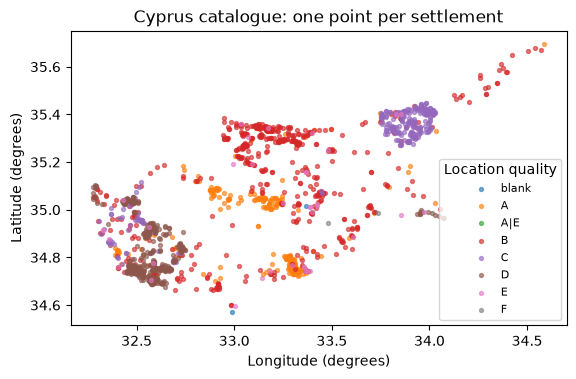

In [19]:
sites = summarise_sites(phases)
assert len(sites) == phases.ID.nunique() == 1559
assert sites.ID.is_unique
assert sites.occupation_rows.sum() == len(phases) == 8766
assert sites.lon.dropna().between(31, 35).all() and sites.lat.dropna().between(34, 36).all()
assert sites.loc[sites.coordinate_conflict, ["lon", "lat"]].isna().all().all()
assert sites.loc[sites.coordinate_conflict, "ID"].tolist() == ["CY453"]
display(sites.groupby(["LocQual", "quality_documented"]).size().rename("sites").to_frame())
print("Undocumented/blank values:", sorted(sites.loc[~sites.quality_documented, "LocQual"].unique()))
display(sites.loc[sites.coordinate_conflict | sites.quality_conflict])
for quality, group in sites.groupby("LocQual"):
    plt.scatter(group.lon, group.lat, s=8, alpha=.6, label=quality or "blank")
plt.xlabel("Longitude (degrees)")
plt.ylabel("Latitude (degrees)")
plt.title("Cyprus catalogue: one point per settlement")
plt.legend(title="Location quality", fontsize=8)
plt.gca().set_aspect(1 / np.cos(np.deg2rad(35)))
plt.show()


**Worked interpretation:** the pinned source has 8,766 occupation rows and 1,559 settlement
IDs. Besides A–E, it contains blank and F values, which the supplied dictionary does not
define. Do not silently interpret F as a quality rank. `CY453` has two distinct coordinate
pairs, so its summary retains the ID and flags the conflict without choosing a point.
Multiple IDs may also share a location,
so deduplicating coordinates alone could erase distinct records. Survey intensity and
historical coverage affect the observed spatial distribution. No catalogue entry does not
mean no archaeology, and known occupation does not imply visibility in today's imagery.

### 9. What happens in Cyprus?

**Question:** does a model trained on Enki give meaningful priorities in a different place
and type of imagery? We apply the Enki-trained DINOv2 classifier unchanged, even if the
baseline won the source comparison, to inspect how that representation transfers.

The sample contains 12 real Sentinel-2 chips from one day in southwest Cyprus: six centred
on catalogue locations and six nearby **unlabelled** locations. Each chip covers 1 km × 1 km
at 10 m per pixel. A catalogue entry does not guarantee that archaeology is visible in the
image; an unlabelled location is not a confirmed absence. Therefore these chips cannot give
us a valid detection-accuracy score.

Background centres were placed 2 km east and checked to be at least 750 m from catalogue
points. Images with less than 90% clear-land pixels were excluded. A larger, independently
labelled geographic study would be needed to measure transfer.

**What changes during transfer?** The model is carried across domains unchanged, but the
imagery and meaning of available labels differ. A catalogue location is not an image-visibility
label, and a nearby background location is not a verified absence. The diagram shows why these
twelve chips support an interpretive review rather than an accuracy estimate.

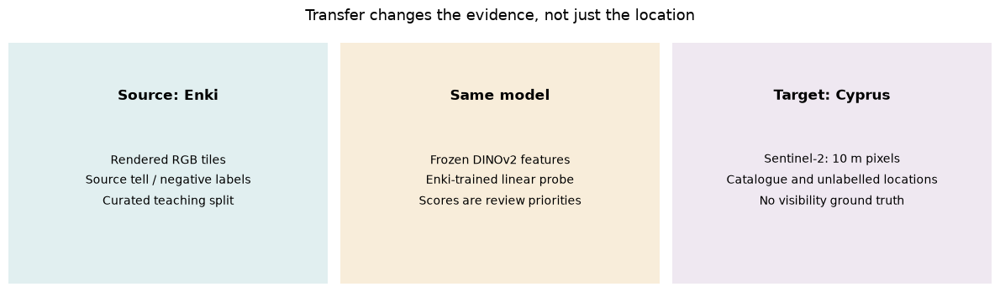

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
cards = [
    ("Source: Enki", "Rendered RGB tiles\nSource tell / negative labels\nCurated teaching split", "#e1eff0"),
    ("Same model", "Frozen DINOv2 features\nEnki-trained linear probe\nScores are review priorities", "#f8edda"),
    ("Target: Cyprus", "Sentinel-2: 10 m pixels\nCatalogue and unlabelled locations\nNo visibility ground truth", "#efe8f1"),
]
for ax, (title, details, colour) in zip(axes, cards):
    ax.set_facecolor(colour)
    ax.text(.5, .78, title, ha="center", va="center", weight="bold", fontsize=12,
            transform=ax.transAxes)
    ax.text(.5, .43, details, ha="center", va="center", fontsize=10,
            linespacing=1.8, transform=ax.transAxes)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.suptitle("Transfer changes the evidence, not just the location", fontsize=13)
fig.tight_layout()
plt.show()


,tile_id,kind,LocQual,gsd_m,clear_land_fraction,score
6,CY5_background,unlabelled_background,A,10,1.0,0.232614
3,CY479_site,catalogued_location,A,10,1.0,0.214828
10,CY754_background,unlabelled_background,A,10,1.0,0.091948
1,CY1451_site,catalogued_location,A,10,1.0,0.091937
4,CY523_background,unlabelled_background,A,10,1.0,0.060103
5,CY523_site,catalogued_location,A,10,1.0,0.042897
8,CY71_background,unlabelled_background,A,10,1.0,0.038963
2,CY479_background,unlabelled_background,A,10,1.0,0.014940
11,CY754_site,catalogued_location,A,10,1.0,0.008700
0,CY1451_background,unlabelled_background,A,10,1.0,0.004883


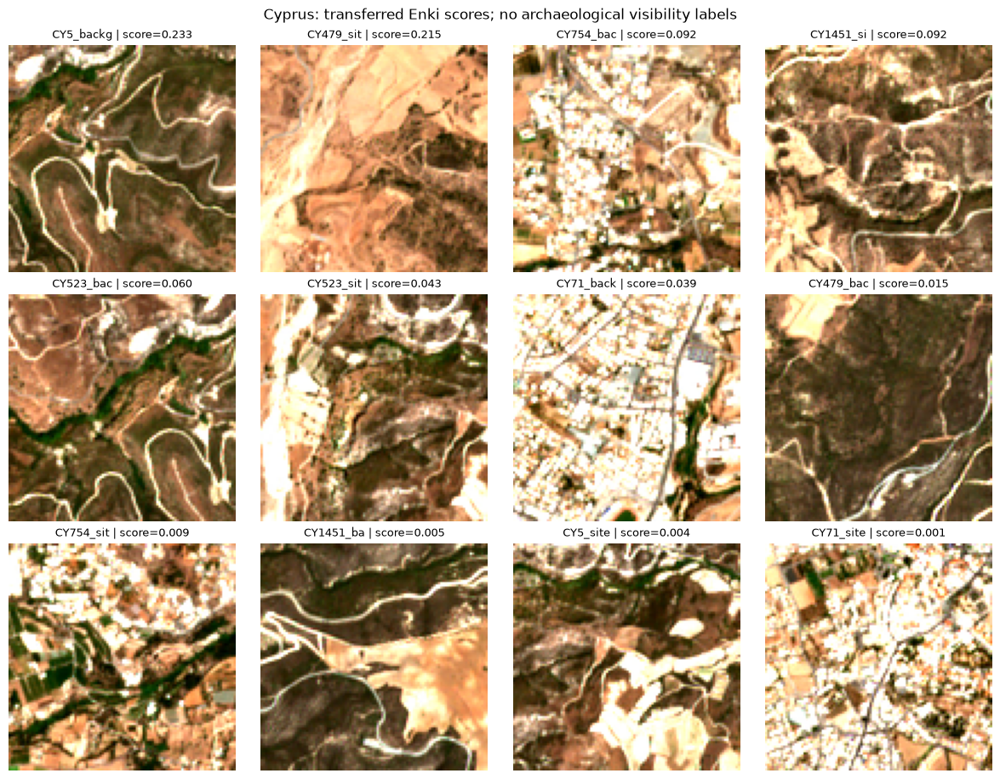

{'item_url': 'https://planetarycomputer.microsoft.com/api/stac/v1/collections/sentinel-2-l2a/items/S2A_MSIL2A_20240805T082601_R021_T36SVD_20240805T144559',
 'item_id': 'S2A_MSIL2A_20240805T082601_R021_T36SVD_20240805T144559',
 'acquisition': '2024-08-05T08:26:01.024000Z',
 'attribution': 'Contains modified Copernicus Sentinel data (2024), accessed through Microsoft Planetary Computer.',
 'interpretation': 'Landscape-context stress test, not archaeological detection ground truth.'}

In [20]:
cyprus_dir = assets / "cyprus"
cyprus = pd.read_csv(cyprus_dir / "manifest.csv")
cyprus["path"] = [str(cyprus_dir / f) for f in cyprus.filename]
with np.load(cyprus_dir / "embeddings.npz", allow_pickle=False) as cache:
    assert np.array_equal(cache["tile_ids"], cyprus.tile_id.to_numpy())
    assert str(cache["revision"]) == MODEL_REVISION
    assert str(cache["preprocessing"]) == PREPROCESS_ID
    cyprus_vectors = cache["embeddings"].copy()
cyprus["score"] = dino_probe.predict_proba(cyprus_vectors)[:, 1]
display(cyprus[["tile_id", "kind", "LocQual", "gsd_m", "clear_land_fraction", "score"]].sort_values("score", ascending=False))
ranked_cyprus = cyprus.sort_values("score", ascending=False)
contact_sheet(ranked_cyprus, ranked_cyprus.score.to_numpy(), n=12,
              title="Cyprus: transferred Enki scores; no archaeological visibility labels", show_labels=False)
display(json.loads((cyprus_dir / "provenance.json").read_text()))
cyprus.to_csv(ROOT / "cyprus_review.csv", index=False)


**Your transfer review:**
1. Compare a high-scoring background and a low-scoring catalogued location.
2. Identify at least three plausible causes of a source-to-Cyprus performance change.
3. Explain why treating all background chips as negatives would invalidate an accuracy claim.
4. Explain whether the scores support morphology detection or landscape-context ranking.
5. Specify the imagery, labels and independent geographic split needed for a real transfer study.

In [21]:
high_bg = cyprus.loc[cyprus.kind == "unlabelled_background"].sort_values("score", ascending=False).iloc[0]
low_site = cyprus.loc[cyprus.kind == "catalogued_location"].sort_values("score").iloc[0]
transfer_review = {
    "high_scoring_background": f"{high_bg.tile_id}: score {high_bg.score:.3f}; this is unlabelled, not a confirmed false positive.",
    "low_scoring_catalogued_location": f"{low_site.tile_id}: score {low_site.score:.3f}; catalogue membership does not establish visible tell morphology.",
    "domain_shift_causes": ["10 m Sentinel-2 versus finer rendered source imagery",
                           "Different RGB rendering and acquisition conditions",
                           "Cypriot settlement types need not resemble source tells",
                           "Landscape, survey coverage and coordinate uncertainty"],
    "why_no_accuracy_score": "We lack image-visibility ground truth and verified negatives. Source probabilities are uncalibrated in this target domain.",
    "next_study": "Acquire licensed finer-resolution multi-date imagery, expert visibility labels and provenance; hold out complete geographic areas and distinct sites, then test ranking at a realistic review budget.",
}
display(transfer_review)


{'high_scoring_background': 'CY5_background: score 0.233; this is unlabelled, not a confirmed false positive.',
 'low_scoring_catalogued_location': 'CY71_site: score 0.001; catalogue membership does not establish visible tell morphology.',
 'domain_shift_causes': ['10 m Sentinel-2 versus finer rendered source imagery',
  'Different RGB rendering and acquisition conditions',
  'Cypriot settlement types need not resemble source tells',
  'Landscape, survey coverage and coordinate uncertainty'],
 'why_no_accuracy_score': 'We lack image-visibility ground truth and verified negatives. Source probabilities are uncalibrated in this target domain.',
 'next_study': 'Acquire licensed finer-resolution multi-date imagery, expert visibility labels and provenance; hold out complete geographic areas and distinct sites, then test ranking at a realistic review budget.'}

### 10. Freeze your choice and prepare your submission

You have chosen a model using validation data. **Freeze it before looking at the test labels.**
Run the next cell to score each test tile and write `submission.csv` and `configuration.json`.
Then fill in the recommendation and run the final cell to create `team_submission.zip`.

The archive is publicly labelled, so this is an educational holdout, not a secure blind test.
Your recommendation should describe the intended use, validation evidence, limitations and
the next study an archaeologist would need.

In [22]:
frozen_configuration = {
    "selected_model": best_key, "seed": SEED, "review_budget": REVIEW_BUDGET,
    "training_tiles": len(train), "test_tiles": len(test),
    "dataset": "Enki Normalized_Tell_combined_350.zip, curated 600-image workshop sample",
    "sample_manifest_sha256": file_digest(assets / "sample_manifest.json"),
    "encoder": MODEL_ID, "encoder_revision": MODEL_REVISION,
    "preprocessing": PREPROCESS_ID, "geographic_independence_verified": False,
}
test_scores = best_model.predict_proba(feature_sets[best_representation]["test"])[:, 1]
submission = write_submission(test, test_scores, ROOT / "submission.csv")
(ROOT / "configuration.json").write_text(json.dumps(frozen_configuration, indent=2))
display(submission.head())
print("Model frozen. Predictions saved to", ROOT / "submission.csv")


,tile_id,score,rank
0,eea5a713c2c66b35,0.999995,1
1,f76b1ac041854f4f,0.999993,2
2,4eb0092ef08a3c43,0.999960,3
3,f3b8b57a94f47a18,0.999951,4
4,fe336ee05755bbef,0.999941,5


Model frozen. Predictions saved to archaeology_workshop/submission.csv


In [23]:
selected = validation_results.iloc[0]
recommendation = {
    "use_case": "Prioritise expert review of imagery similar to the source dataset.",
    "validation_evidence": f"{best_key}: validation recall@{REVIEW_BUDGET}={selected.recall_at_k:.3f}; AP={selected.AP:.3f}.",
    "main_limitations": ["Image-similarity split is not a geographic holdout",
                         "Curated class prevalence differs from operational survey prevalence",
                         "Cyprus sample lacks archaeological visibility labels",
                         "10 m context is insufficient for many small archaeological features"],
    "what_we_would_do_next": "Commission an independently labelled geographic holdout and audit high-priority candidates with an archaeologist before allocating field survey.",
}
display(recommendation)


{'use_case': 'Prioritise expert review of imagery similar to the source dataset.',
 'validation_evidence': 'dinov2_C1: validation recall@50=0.833; AP=0.996.',
 'main_limitations': ['Image-similarity split is not a geographic holdout',
  'Curated class prevalence differs from operational survey prevalence',
  'Cyprus sample lacks archaeological visibility labels',
  '10 m context is insufficient for many small archaeological features'],
 'what_we_would_do_next': 'Commission an independently labelled geographic holdout and audit high-priority candidates with an archaeologist before allocating field survey.'}

In [24]:
report = {"error_analysis": error_notes, "transfer_review": transfer_review,
          "recommendation": recommendation}
(ROOT / "team_report.json").write_text(json.dumps(report, indent=2))
output_zip = ROOT / "team_submission.zip"
with zipfile.ZipFile(output_zip, "w", zipfile.ZIP_DEFLATED) as out:
    for name in ("submission.csv", "configuration.json", "validation_results.csv",
                 "learning_curve.csv", "cyprus_review.csv", "team_report.json"):
        out.write(ROOT / name, name)
print("Download", output_zip, "from Colab's Files panel; save your completed notebook too.")


Download archaeology_workshop/team_submission.zip from Colab's Files panel; save your completed notebook too.


### 11. Reveal the final result

After you have submitted, ask the facilitator when to change `REVEAL_TEST` to `True` and run
the cell. Do not use this result to choose a replacement model: the test is the final check.
Recall counts positive **tiles**, not independently verified sites. The random-ranking
comparison is a reference for this small, balanced sample, not operational prevalence.

AP                 0.961681
recall_at_k        0.816667
precision_at_k     0.980000
hits              49.000000
reviewed          50.000000
Name: final_holdout, dtype: float64

Random ranking expected recall: 0.42016806722689076
Random ranking expected precision: 0.5042016806722689


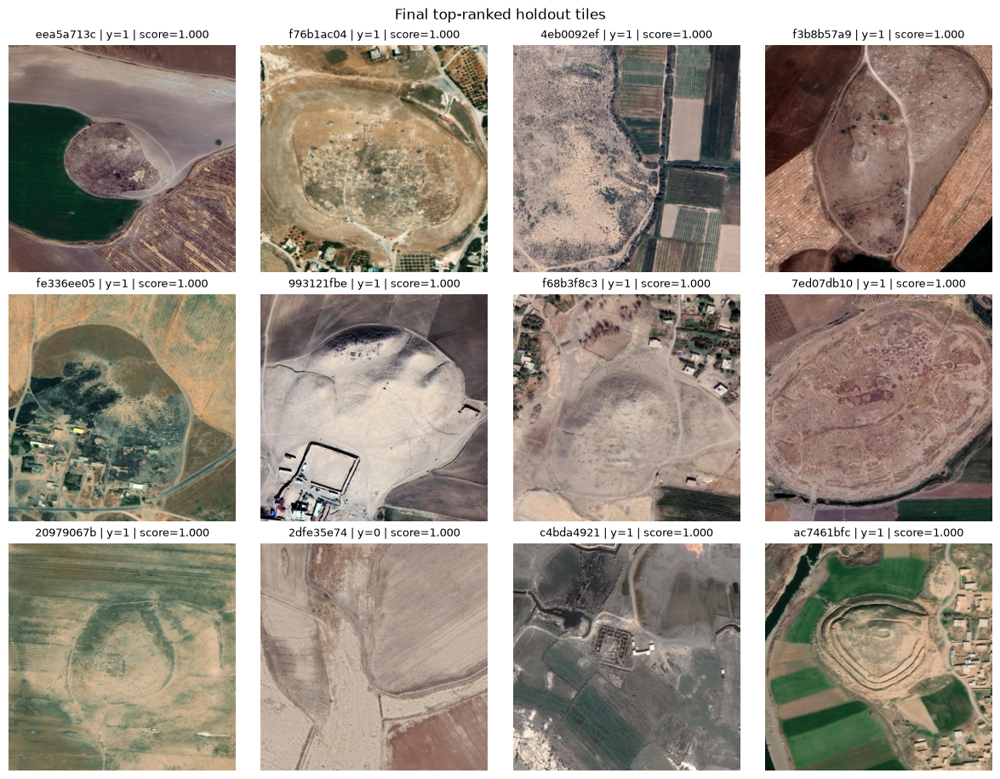

In [25]:
REVEAL_TEST = True
if REVEAL_TEST:
    final_metrics = score_submission(submission, test, ranking_metrics, REVIEW_BUDGET)
    display(pd.Series(final_metrics, name="final_holdout"))
    print("Random ranking expected recall:", min(REVIEW_BUDGET, len(test)) / len(test))
    print("Random ranking expected precision:", test.label.mean())
    # A single diagnostic view after the model was frozen.
    order = ranking_indices(test_scores)
    contact_sheet(test.iloc[order], test_scores[order], n=12, title="Final top-ranked holdout tiles")
else:
    print("Test reveal disabled. Submit before asking the facilitator to reveal.")


### Instructor: debrief and marking guide
- **50% ranking:** compare held-out recall at the same 50-tile budget; use AP to break ties.
- **30% reasoning:** recognise unresolved spatial leakage, label/visibility differences,
  source-prevalence effects and the resolution mismatch in Cyprus.
- **20% reproducibility:** correct ID-aligned CSV, pinned provenance, reproducible notebook
  and a concise recommendation supported by measured results.

A participant may reasonably recommend against operational deployment. Reward that
conclusion when the evidence supports it. The model is an image-ranking aid; it cannot
establish chronology, burial, legal status or the presence of a previously unknown site.

Expected exercise outcomes: correct top-k denominators; scaling fitted on training only;
model selection on validation only; 1,559 distinct Cyprus IDs; blank/F quality codes and
the conflicting coordinates for `CY453` flagged;
no numerical transfer-accuracy claim from the unlabelled background sample.

### Optional instructor refresh of the Cyprus bundle
The normal notebook uses the embedded sample, so a live imagery service is not required
during class. The helper `make_cyprus_bundle` above contains the complete acquisition
and feature-extraction recipe. To regenerate it, enable the following cell. This downloads
public COG windows and the pinned model, and needs additional network access.
It does not overwrite the bundled results used above.

In [26]:
REFRESH_CYPRUS = False
if REFRESH_CYPRUS:
    install_packages("rasterio>=1.3,<2", "planetary-computer==1.0.0", "transformers==4.57.6")
    regenerated = make_cyprus_bundle(phases, ROOT / "refreshed_cyprus")
    display(regenerated)


### Sources, provenance and attribution
- Crawford & Vella (2022), [Cyprus Dataset: Settlements from 11000 BCE to 1878 CE](https://doi.org/10.5334/joad.96).
  [Source repository](https://github.com/K-A-Crawford/Cyprus_Settlements), pinned revision
  `70a5c3d399a2451e1d8dd5eb947eb80055276b44`. Dataset: CC BY 4.0.
- Rosati (2025), [Enki: AI for Archaeology — datasets](https://zenodo.org/records/14950565).
  We sample `Normalized_Tell_combined_350.zip` (published whole-archive MD5
  `1d4ea398ea5669f9bca4539416847206`). Partial downloads verify member CRCs and pixel hashes,
  not the full archive MD5. The embedded manifest records every selected member and byte range.
  The record declares CC BY-SA 4.0 and separately describes Google/Bing imagery provenance
  and provider conditions. Retain those notices when reusing its imagery or derived materials.
- Oquab et al., [DINOv2](https://github.com/facebookresearch/dinov2) and
  [model card](https://huggingface.co/facebook/dinov2-small). Model revision and preprocessing
  are recorded in the cache. The workshop adds no encoder fine-tuning.
- Cyprus chips: contains modified Copernicus Sentinel data (2024), accessed through
  [Microsoft Planetary Computer](https://planetarycomputer.microsoft.com/dataset/sentinel-2-l2a).
  Scene `S2A_MSIL2A_20240805T082601_R021_T36SVD_20240805T144559`.
  No commercial imagery account or Earth Engine authentication is needed for this sample.
- Follow-on EO model: [RemoteCLIP](https://github.com/ChenDelong1999/RemoteCLIP).
  It is not used to generate this notebook's reported results.

**Troubleshooting:** if Zenodo is temporarily unavailable or refuses byte ranges, use the
facilitator's `enki_workshop_sample.zip` in `archaeology_workshop/`; the member checks still
apply. Do not put the original full archive at that path. A restarted runtime loses local outputs
unless you download them. If a helper
name is undefined, rerun setup and the infrastructure cells in order. For the default path,
leave GPU recomputation and live Cyprus refresh disabled.